# Dynamic Optimization with Collocation and Pyomo.DAE
**Prepared by:** Prof. Alexander Dowling, Molly Dougher (mdoughe6@nd.edu, 2023)

```{warning}
**AI-drafted prose, not yet reviewed by Prof. Dowling.**

Some of the writing on this page was drafted or edited by an AI assistant and has not yet been reviewed: 12 rewritten and 4 added markdown cells, measured against the last version of this notebook predating AI editing (2026-08-17).

This notice is about the *prose only*. It says nothing either way about the code, the numbers or the figures, which are checked separately. It is removed once the page has been reviewed.
```

In [1]:
# Install Pyomo and solvers for Google Colab
import sys

if "google.colab" in sys.modules:
    !wget "https://raw.githubusercontent.com/ndcbe/optimization/main/notebooks/helper.py"
    import helper

    helper.easy_install()
else:
    sys.path.insert(0, "../")
    import helper
helper.set_plotting_style()

import numpy as np
import matplotlib.pyplot as plt

## Guide to the transcription

Use this page for the full derivation behind Lecture 7: [polynomial coordinates](#collocation-state-basis), [integrated derivative basis and Runge-Kutta equations](#collocation-rk-proof), [continuity and counting](#collocation-connectivity), [time scaling and implementation](#collocation-time-scaling), and [sparse structure](#collocation-sparsity).

The existing quadrature implementation below remains useful for experiments. The orthogonality proof is taught in the numerical-integration lecture and developed in [](./DAE_numeric_integration.ipynb). For exact coefficient construction, see [](./Collocation_Coefficients.ipynb); for a solved model, see [](./PyomoDAE_car.ipynb).

Primary sources: Biegler (2010), Chapter 8, p. 216, and Chapter 10, pp. 289–298, with the Chapter 10 errata; Ascher & Petzold (1998), Section 4.7, pp. 101–104.

We now turn a DAE-constrained dynamic optimization problem into a sparse nonlinear program. We approximate state and control profiles with piecewise polynomials and enforce the DAE at collocation points. This simultaneous, or direct-transcription, approach is closely related to the implicit Runge--Kutta methods developed in the numerical-integration lecture.


## Quadrature Methods

We begin with the quadrature ideas needed to derive collocation. The next notebooks apply the method to dynamic optimization examples. For more detail, see:

* Chapter 9 in [Biegler (2010)](https://epubs.siam.org/doi/book/10.1137/1.9780898719383)
* Chapter 16, *Gauss Quadrature and Multi-dimensional Integrals*, in [McClarren (2018)](https://www.sciencedirect.com/book/9780128122532/computational-nuclear-engineering-and-radiological-science-using-python)

### Main Idea

The quadrature rule approximates the integral $I$ with weighted sum of function evaluations:

$$\begin{equation*}
I := \int_{-1}^{1} f(x) dx \approx \underbrace{\sum_{l=1}^{L} w_l f(x_l)}_{\text{quadrature rule}}
\end{equation*}$$

where:
* $x_l$ are nodes (also known as abscissas)
* $w_l$ are weights
* $L$ number of nodes and weights

Central questions:
* How to choose *nodes* and *weights*?
* How does this choice impact approximation error?
* How does $L$ impact approximation error?

### Polynomial degree and coefficient count

A polynomial $p(t)=\sum_{j=0}^K a_jt^j$ has $K+1$ coefficients and degree at most $K$, with equality when $a_K\ne0$. Some older texts call that polynomial “order $K+1$.” Here *degree* denotes the highest power; *order* denotes the rate at which a numerical error decreases.

### Gauss-Legendre quadrature

With the Gauss-Legendre nodes and weights, the $L$-point rule is exact for every polynomial of degree at most $2L-1$. No $L$-node rule with real nodes can be exact through degree $2L$: the squared node polynomial $\prod_l(x-x_l)^2$ is zero at all nodes but has a positive integral. This is optimal **polynomial exactness**, rather than a claim of minimum error for every nonpolynomial integrand.

The table gives nodes and weights for $L\le8$.

| $L$  |  $x_l$ | $w_l$ |
| ---- | ------ | ----- |
| 1 | 0 | 2.0 |
| 2 | ±0.5773502691896257645091488 | 1.0 | 
| 3 | 0                            | 0.8888888888888888888888889 |  
|   | ±0.7745966692414833770358531 | 0.5555555555555555555555556 |
| 4 | ±0.3399810435848562648026658 | 0.6521451548625461426269361 |  
|   | ±0.8611363115940525752239465 | 0.3478548451374538573730639 | 
| 5 | 0                            | 0.5688888888888888888888889 |  
|   | ±0.5384693101056830910363144 | 0.4786286704993664680412915 |  
|   | ±0.9061798459386639927976269 | 0.2369268850561890875142640 | 
| 6 | ±0.2386191860831969086305017 | 0.4679139345726910473898703 |
|   | ±0.6612093864662645136613996 | 0.3607615730481386075698335 |
|   | ±0.9324695142031520278123016 | 0.1713244923791703450402961 |
| 7 | 0                            | 0.4179591836734693877551020 |
|   | ±0.4058451513773971669066064 | 0.3818300505051189449503698 |
|   | ±0.7415311855993944398638648 | 0.2797053914892766679014678 |
|   | ±0.9491079123427585245261897 | 0.1294849661688696932706114 | 
| 8 | ±0.1834346424956498049394761 | 0.3626837833783619829651504 |
|   | ±0.5255324099163289858177390 | 0.3137066458778872873379622 |
|   | ±0.7966664774136267395915539 | 0.2223810344533744705443560 |
|   | ±0.9602898564975362316835609 | 0.1012285362903762591525314 |

### Why $2L-1$?

Let $f(x) = a_{2L-1} x^{2L-1} + a_{2L-2} x^{2L-2} + ... + a_{1} x^1 + a_{0}$

Exactness through degree $2L-1$ imposes $2L$ moment equations (one for each monomial $1,x,\ldots,x^{2L-1}$). These match the $2L$ unknown node and weight values in an $L$-point rule. This count motivates the attainable degree; orthogonal-polynomial theory supplies the nodes and proves exactness.

### How to determine the nodes and weights? 

One way to derive the Gauss-Legendre quadrature rules is by looking at the integral generic monomials of degree 0 up to $2L-1$ and setting each equal to the $L$ point Gauss-Legendre quadrature rule:

$$ \begin{align*} \int\limits_{-1}^{1} dx\, a_0 x^0 &=  a_0\sum_{l=1}^L w_l x_l^0, \\
\int\limits_{-1}^{1} dx\, a_1 x^1 &= a_1\sum_{l=1}^L w_l x_l^1, \\
& ~~ \vdots \\
\int\limits_{-1}^{1} dx\, a_{2L-1} x^{2L-1} &= a_{2L-1}\sum_{l=1}^L w_l x_l^{2L-1}.
\end{align*}
$$
Notice that the $a_i$ **constants cancel out** of each equation so they do not matter. This system is $2L$ equations with $L$ weights, $w_l$, and $L$ nodes, $x_l$. We could solve these equations to get the weights and nodes, though this is not how it is done in practice generally---this is accomplished by using the theory of orthogonal polynomials.

### Code

In [2]:
def GLQuad(f, L=8, dataReturn=False):
    """Compute the Gauss-Legendre Quadrature estimate
    of the integral of f(x) from -1 to 1
    Inputs:
    f:   name of function to integrate
    L:   Number of quadrature nodes. Tabulated here for L <= 8;
         larger L falls through to numpy.polynomial.legendre.leggauss.
    dataReturn:   determines whether weights and xs are returned

    Returns:
    G-L Quadrature estimate"""

    # Set bound on L
    assert L >= 1

    # Enumerate over L to define weights and x in each scenario
    if L == 1:
        weights = np.ones(1) * 2
        xs = np.array([0])
    elif L == 2:
        weights = np.ones(2)
        xs = np.array([-np.sqrt(1.0 / 3.0), np.sqrt(1.0 / 3.0)])
    elif L == 3:
        weights = np.array(
            [
                0.8888888888888888888888889,
                0.5555555555555555555555556,
                0.5555555555555555555555556,
            ]
        )
        xs = np.array([0.0, -0.7745966692414833770358531, 0.7745966692414833770358531])
    elif L == 4:
        weights = np.array(
            [
                0.6521451548625461426269361,
                0.6521451548625461426269361,
                0.3478548451374538573730639,
                0.3478548451374538573730639,
            ]
        )
        xs = np.array(
            [
                -0.3399810435848562648026658,
                0.3399810435848562648026658,
                -0.8611363115940525752239465,
                0.8611363115940525752239465,
            ]
        )
    elif L == 5:
        weights = np.array(
            [
                0.5688888888888888888888889,
                0.4786286704993664680412915,
                0.4786286704993664680412915,
                0.2369268850561890875142640,
                0.2369268850561890875142640,
            ]
        )
        xs = np.array(
            [
                0.0,
                -0.5384693101056830910363144,
                0.5384693101056830910363144,
                -0.9061798459386639927976269,
                0.9061798459386639927976269,
            ]
        )
    elif L == 6:
        weights = np.array(
            [
                0.4679139345726910473898703,
                0.4679139345726910473898703,
                0.3607615730481386075698335,
                0.3607615730481386075698335,
                0.1713244923791703450402961,
                0.1713244923791703450402961,
            ]
        )
        xs = np.array(
            [
                -0.2386191860831969086305017,
                0.2386191860831969086305017,
                -0.6612093864662645136613996,
                0.6612093864662645136613996,
                -0.9324695142031520278123016,
                0.9324695142031520278123016,
            ]
        )
    elif L == 7:
        weights = np.array(
            [
                0.4179591836734693877551020,
                0.3818300505051189449503698,
                0.3818300505051189449503698,
                0.2797053914892766679014678,
                0.2797053914892766679014678,
                0.1294849661688696932706114,
                0.1294849661688696932706114,
            ]
        )
        xs = np.array(
            [
                0.0,
                -0.4058451513773971669066064,
                0.4058451513773971669066064,
                -0.7415311855993944398638648,
                0.7415311855993944398638648,
                -0.9491079123427585245261897,
                0.9491079123427585245261897,
            ]
        )
    elif L == 8:
        weights = np.array(
            [
                0.3626837833783619829651504,
                0.3626837833783619829651504,
                0.3137066458778872873379622,
                0.3137066458778872873379622,
                0.2223810344533744705443560,
                0.2223810344533744705443560,
                0.1012285362903762591525314,
                0.1012285362903762591525314,
            ]
        )
        xs = np.array(
            [
                -0.1834346424956498049394761,
                0.1834346424956498049394761,
                -0.5255324099163289858177390,
                0.5255324099163289858177390,
                -0.7966664774136267395915539,
                0.7966664774136267395915539,
                -0.9602898564975362316835609,
                0.9602898564975362316835609,
            ]
        )
    else:  # use numpy's function
        xs, weights = np.polynomial.legendre.leggauss(L)

    # Calculate the quadrature estimate
    quad_estimate = np.sum(weights * f(xs))

    if dataReturn:
        return quad_estimate, weights, xs
    else:
        return quad_estimate

### Visualize Weights

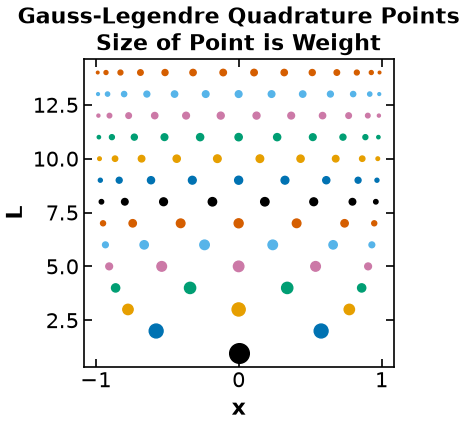

In [3]:
# Establish L
L = np.arange(1, 15)
# Define a lambda function
f = lambda x: x

# Define the figure
plt.figure(figsize=(4, 4))

# Loop over L
for l in L:
    # Calculate quadrature estimate
    quad_est, weights, xs = GLQuad(f, l, dataReturn=True)
    levels = weights * 0 + l
    plt.scatter(xs, levels, s=weights * 100)

# Format the plot
plt.xlabel("x", fontsize=16, fontweight="bold")
plt.ylabel("L", fontsize=16, fontweight="bold")
plt.tick_params(direction="in", labelsize=15)
plt.title(
    "Gauss-Legendre Quadrature Points\nSize of Point is Weight",
    fontsize=16,
    fontweight="bold",
)
plt.show()

### Polynomial Example

As a simple demonstration of the Gauss-Legendre quadrature, let's show that it integrates polynomials of degree $2L-1$ exactly.  Consider the integral
$$\int\limits_{-1}^1 (x+1)^{2L-1}\,dx = \frac{2^{2 L-1}}{L}.$$

We can use the GLQuad function to evaluate the error.

In [4]:
L = np.arange(1, 12)
for l in L:

    # Create f
    f = lambda x: (x + 1) ** (2 * l - 1)

    # Evaluate exact (analytic) solution
    integral = 2 ** (2 * l - 1) / l

    # Evaluate quadrature rule
    GLintegral = GLQuad(f, l)

    # Print results
    print(
        "L =",
        l,
        "\t Estimate is",
        GLintegral,
        "Exact value is",
        integral,
        "\nAbs. Relative Error is",
        np.abs(GLintegral - integral) / integral,
    )

L = 1 	 Estimate is 2.0 Exact value is 2.0 
Abs. Relative Error is 0.0
L = 2 	 Estimate is 3.9999999999999996 Exact value is 4.0 
Abs. Relative Error is 1.1102230246251565e-16
L = 3 	 Estimate is 10.666666666666668 Exact value is 10.666666666666666 
Abs. Relative Error is 1.6653345369377348e-16
L = 4 	 Estimate is 31.99999999999999 Exact value is 32.0 
Abs. Relative Error is 3.3306690738754696e-16
L = 5 	 Estimate is 102.39999999999995 Exact value is 102.4 
Abs. Relative Error is 5.551115123125783e-16
L = 6 	 Estimate is 341.33333333333337 Exact value is 341.3333333333333 
Abs. Relative Error is 1.6653345369377348e-16
L = 7 	 Estimate is 1170.2857142857135 Exact value is 1170.2857142857142 
Abs. Relative Error is 5.828670879282072e-16
L = 8 	 Estimate is 4096.000000000003 Exact value is 4096.0 
Abs. Relative Error is 6.661338147750939e-16
L = 9 	 Estimate is 14563.555555555482 Exact value is 14563.555555555555 
Abs. Relative Error is 4.9960036108132044e-15
L = 10 	 Estimate is 52428.79

### Generalization

We are generally interested in integrals not just over the domain $x\in [-1,1]$.  We'll now make a function that does Gauss-Legendre quadrature over a general range using the formula
$$\int_a^b f(x)\,dx = \frac{b-a}{2} \int_{-1}^1 f\left(\frac{b-a}{2}z + \frac{a+b}{2}\right)\,dz.$$

In [5]:
def generalGL(f, a, b, L):
    """Compute the Gauss-Legendre Quadrature estimate
    of the integral of f(x) from a to b
    Inputs:
    f:   name of function to integrate
    a:   lower bound of integral
    b:   upper bound of integral
    L:   Number of quadrature nodes (see GLQuad)
    Returns:
    G-L Quadrature estimate"""

    # Set bound on L
    assert L >= 1

    # Define a re-scaled f
    f_rescaled = lambda z: f(0.5 * (b - a) * z + 0.5 * (a + b))

    # Define the integral
    integral = GLQuad(f_rescaled, L)

    # Calculate the G-L quadrature estimate
    return integral * (b - a) * 0.5

Let's show that this version integrates polynomials of degree $2L-1$ exactly.  Consider the integral
$$\int\limits_{-3}^2 (x+1)^{2L-1}\,dx = \frac{9^L-4^L}{2 L}.$$

In [6]:
L = np.arange(1, 12)

# Loop over L to calculate the integral and the G-L estimate
for l in L:
    # Define a lambda function
    f = lambda x: (x + 1) ** (2 * l - 1)
    # Calculate the integral
    integral = (9**l - 4**l) / (2 * l)
    # Calculate the estimate
    GLintegral = generalGL(f, -3, 2, l)
    # Print statement for the error comparison
    print(
        "L =",
        l,
        "\t Estimate is",
        GLintegral,
        "Exact value is",
        integral,
        "\nAbs. Relative Error is",
        np.abs(GLintegral - integral) / integral,
    )

L = 1 	 Estimate is 2.5 Exact value is 2.5 
Abs. Relative Error is 0.0
L = 2 	 Estimate is 16.249999999999996 Exact value is 16.25 
Abs. Relative Error is 2.1862853408003084e-16
L = 3 	 Estimate is 110.83333333333336 Exact value is 110.83333333333333 
Abs. Relative Error is 2.5643647606379557e-16
L = 4 	 Estimate is 788.1249999999999 Exact value is 788.125 
Abs. Relative Error is 1.4424975444455643e-16
L = 5 	 Estimate is 5802.500000000002 Exact value is 5802.5 
Abs. Relative Error is 3.1348374037843283e-16
L = 6 	 Estimate is 43945.4166666667 Exact value is 43945.416666666664 
Abs. Relative Error is 8.278403262589113e-16
L = 7 	 Estimate is 340470.35714285733 Exact value is 340470.35714285716 
Abs. Relative Error is 5.128874777992276e-16
L = 8 	 Estimate is 2686324.0625 Exact value is 2686324.0625 
Abs. Relative Error is 0.0
L = 9 	 Estimate is 21508796.944444306 Exact value is 21508796.944444444 
Abs. Relative Error is 6.408342660870799e-15
L = 10 	 Estimate is 174286791.24999845 Exa

### Radau Quadrature

Sometimes we desire either:
* The first node is at the beginning of the interval, i.e., $x_1 = -1$ or
* The last node is at the end of the interval, i.e., $x_{L} = 1$.

This is known as **Gauss-Radau quadrature**. The remaining nodes and weights are chosen optimally; thus, Radau quadrature *exactly* integrates *all* polynomials of degree $2L-2$ or less. Specifying one of the nodes leaves only $2L-1$ degrees of freedom.

More info: https://mathworld.wolfram.com/RadauQuadrature.html


### Differential Equations

Consider solving the differential equation

$$\dot{\mathbf{x}} = \mathbf{f}(t,\mathbf{x}), \quad \mathbf{x}(t_0) = \mathbf{x}_0,$$

to determine $\mathbf{x}(t_f)$. This can be expressed as an integral:

$$\mathbf{x}(t_f) = \int_{t_0}^{t_f} \frac{d\mathbf{x}}{dt} dt + \mathbf{x}_0 = \underbrace{\int_{t_0}^{t_f} \mathbf{f}(t, \mathbf{x}(t)) dt}_{\text{quadrature rule}} + \mathbf{x}_0$$

Thus, Runge-Kutta methods can be interpreted as a quadrature rule.

## Collocation Methods
See the following resources for more information on collocation:
* Chapter 10 in [Biegler (2010)](https://epubs.siam.org/doi/book/10.1137/1.9780898719383)

### What is a Collocation Method?
https://encyclopediaofmath.org/wiki/Collocation_method

A collocation method approximates the state with a polynomial and enforces the differential and algebraic equations at selected collocation points. The resulting finite system of algebraic equations can be solved directly or embedded in an optimization problem.

### Derivation of Collocation Methods
*Derivations are followed from Section 10.2 of Biegler (2010).*

Consider the following multiperiod dynamic optimization problem (8.5).

\begin{align*}
\min & \sum_{l=1}^{N_T} \Phi^l\left(\mathbf{z}^l\left(t_l\right), \mathbf{y}^l\left(t_l\right), \mathbf{u}^l\left(t_l\right), \mathbf{p}^l\right) \\
\text { s.t. } & \frac{d \mathbf{z}^l}{d t}=\mathbf{f}^l\left(\mathbf{z}^l(t), \mathbf{y}^l(t), \mathbf{u}^l(t), \mathbf{p}^l\right), \quad \mathbf{z}^l\left(t_{l-1}\right)=\mathbf{z}_0^l, \\
& \mathbf{g}^l\left(\mathbf{z}^l(t), \mathbf{y}^l(t), \mathbf{u}^l(t), \mathbf{p}^l\right)=\mathbf{0}, \\
& \mathbf{u}_L^l \leq \mathbf{u}^l(t) \leq \mathbf{u}_U^l, \\
& \mathbf{p}_L^l \leq \mathbf{p}^l \leq \mathbf{p}_U^l, \\
& \mathbf{y}_L^l \leq \mathbf{y}^l(t) \leq \mathbf{y}_U^l, \\
& \mathbf{z}_L^l \leq \mathbf{z}^l(t) \leq \mathbf{z}_U^l, \quad t \in\left(t_{l-1}, t_l\right], l=1, \ldots, N_T, \\
& \mathbf{h}\left(\mathbf{p}, \mathbf{z}_0^1, \mathbf{z}^1\left(t_1\right), \mathbf{z}_0^2, \mathbf{z}^2\left(t_2\right), \ldots, \mathbf{z}_0^{N_T}, \mathbf{z}^{N_T}\left(t_{N_T}\right)\right)=\mathbf{0}
\end{align*}

Each physical period $l$ may contain many finite elements. Period junctions use the coupling function $\mathbf h$; finite-element boundaries within a period use state continuity. The decision variables include the nodal states, control coefficients and any free parameters. A running cost can be included by adding an accumulator state, $\dot q=L(\mathbf z,\mathbf y,\mathbf u,\mathbf p,t)$, and minimizing $q(t_f)$ plus terminal cost.
 
![Polynomial state profile on one finite element, with interpolation values at normalized collocation coordinates.](https://raw.githubusercontent.com/ndcbe/optimization/main/media/figures/collocation-finite-element.svg)

This source-controlled course schematic was re-authored from the mathematical layout of Biegler (2010), Figure 10.1; it is not a reproduction of the textbook artwork.


(collocation-state-basis)=
### State coordinates on one element

The collocation method can be developed by solving the differential equation ($ dz/dt $) at specific time points. For example, Figure 10.1 shows the state variable approximation for a single finite element:

\begin{align}
\mathbf{z}^K(t) = \boldsymbol\alpha_0 + \boldsymbol\alpha_1t + \cdots + \boldsymbol\alpha_Kt^K 
\end{align}

The coefficients $\boldsymbol\alpha_j$ are vectors when the state is a vector. A power basis is mathematically valid, but nodal Lagrange coefficients are directly interpretable as state values. This profile can also be represented as a Lagrange interpolation polynomial. For Gauss-Legendre or right Radau, choose $K+1$ distinct interpolation points within element $i$, the state can be represented as:

\begin{align}
& t = t_{i-1} + h_i\tau , \\
& \mathbf{z}^K(t) = \sum_{j=0}^K \ell_j(\tau)\mathbf{z}_{ij} , \\
& \text{for } t \in [t_{i-1},t_i] \text{ and } \tau \in [0,1] , \\
& \text{where } \ell_j(\tau) = \prod_{\substack{k=0 \\ k\neq j}}^K \frac{(\tau-\tau_k)}{(\tau_j-\tau_k)} \\
& \tau_0=0 \\
& \tau_j<\tau_{j+1}, \\
& j=0,...,K-1 , \\
& \text{and } h_i \text{ is the length of element } i. \\
\end{align}

The key property of this polynomial is that
$ z^K(t_{ij})=z_{ij} $ where $ t_{ij}=t_{i-1} + \tau_j h_i $.


At $\tau=\tau_k$, every $\ell_j$ with $j\ne k$ contains a zero numerator; $\ell_k(\tau_k)=1$. Thus $\mathbf z^K(t_{ik})=\mathbf z_{ik}$. The basis also satisfies $\sum_j\ell_j=1$: both sides interpolate the constant polynomial at $K+1$ distinct nodes. These identities justify interpreting coefficients as nodal values.

![Lagrange basis curves at three Radau nodes and the incoming point; the curves reproduce the nodal values.](https://raw.githubusercontent.com/ndcbe/optimization/ab98f212916b51ed5ee9901dfbc57290f6fd9fe4/media/figures/collocation-lagrange-basis.png)

**Why change coordinates?** Power coefficients are not nodal states, so componentwise bounds on those coefficients do not directly impose physical state bounds. Monomial Vandermonde systems can also become poorly conditioned as the degree grows or the time interval is badly scaled; nearly dependent columns make coefficients sensitive even when the represented profile changes little. Normalizing each element and using nodal coordinates makes the variables easier to interpret. It does not remove every conditioning problem, and nodal bounds still need the between-node check below.

**Bounds are nodal.** Imposing $\mathbf z_L\le\mathbf z_{ij}\le\mathbf z_U$ does not bound the whole polynomial. Lagrange basis functions can be negative between nodes. Check additional points, extrema of the interpolation polynomial, or the independently integrated trajectory. For a continuous path constraint, mesh refinement and a residual check are part of validation.

The counterexample below uses $p(\tau)=4.2\tau(1-\tau)$ at the initial point and three right-Radau nodes. Every nodal value lies in $[0,1]$, but $p(1/2)=1.05$.

In [7]:
radau = np.array([(4-np.sqrt(6))/10,(4+np.sqrt(6))/10,1.0])
nodes = np.r_[0.0,radau]
values = 4.2*nodes*(1-nodes)
assert np.all((values>=0)&(values<=1))
assert np.isclose(4.2*0.5*(1-0.5),1.05)
print("Nodal values:",values,"; value at tau=1/2:",1.05)

Nodal values: [0.         0.55024286 0.96175714 0.        ] ; value at tau=1/2: 1.05


(collocation-rk-proof)=
## Integrated derivative basis gives Runge-Kutta equations

Let $K$ distinct derivative nodes be $c_j$. Define
$$\bar\ell_j(\tau)=\prod_{k\ne j}\frac{\tau-c_k}{c_j-c_k},\qquad
\Omega_j(\tau)=\int_0^\tau\bar\ell_j(s)\,ds.$$
The derivative polynomial has degree at most $K-1$; integrating it with the initial value gives
$$\mathbf z^K(t_{i-1}+h_i\tau)=\mathbf z_{i-1}+h_i\sum_{k=1}^K\Omega_k(\tau)\mathbf v_{ik}.$$
Here $\mathbf v_{ik}$ denotes the **physical-time derivative**, not the state. Differentiating cancels the factor $h_i$, and $\bar\ell_k(c_j)=\delta_{kj}$ gives $d\mathbf z^K/dt(t_{ij})=\mathbf v_{ij}$. The factor arises from $dt=h_i\,d\tau$.

![Integrating a derivative basis accumulates area and reconstructs the state from the incoming value.](https://raw.githubusercontent.com/ndcbe/optimization/ab98f212916b51ed5ee9901dfbc57290f6fd9fe4/media/figures/col-integrated-basis.png)

For a semi-explicit DAE, enforce
$$\mathbf v_{ij}=\mathbf f(\mathbf Z_{ij},\mathbf Y_{ij},\mathbf U_{ij},\mathbf p,t_{ij}),\qquad
\mathbf0=\mathbf g(\mathbf Z_{ij},\mathbf Y_{ij},\mathbf U_{ij},\mathbf p,t_{ij}).$$
Evaluating the state at the stages and endpoint gives
$$\begin{aligned}
\mathbf Z_{ij}&=\mathbf z_{i-1}+h_i\sum_k a_{jk}\mathbf f_{ik},&a_{jk}&=\Omega_k(c_j),\\
\mathbf z_i&=\mathbf z_{i-1}+h_i\sum_k b_k\mathbf f_{ik},&b_k&=\Omega_k(1).
\end{aligned}$$
These are the Runge-Kutta stage and update equations. For a state-only ODE they are standard RK; for a DAE the algebraic stage equations are additional. A degree-$K$ state polynomial is fixed by its initial value and its derivative at $K$ distinct points, so this derivative representation is equivalent to the state-coordinate equations when the state interpolation nodes are distinct.

**Not every node set is implicit.** For one node $c$, $a_{11}=c$ and $b_1=1$. The choices $c=0,1/2,1$ give forward Euler, implicit midpoint and backward Euler. Standard Gauss, Radau IIA and Lobatto IIIA are implicit families (the first Lobatto stage is an explicit evaluation). For Lobatto the derivative nodes include zero; do not append a duplicate zero to the $K+1$-point state formula.

**Partition of unity gives stage times.** Since $\sum_k\bar\ell_k=1$, $\sum_k\Omega_k(\tau)=\tau$. Hence $\mathbf A\mathbf1=\mathbf c$ and $\mathbf b^T\mathbf1=1$. For $dt/dt=1$ this reproduces $t_{ij}=t_{i-1}+h_ic_j$ and $t_i=t_{i-1}+h_i$. With normalized local coordinate, $dt/d\tau=h_i$, not 1. Always use $b_k$ for the endpoint update; the last row of $\mathbf A$ equals $\mathbf b^T$ only when the last node is 1.

(collocation-connectivity)=
## Continuity and degree-of-freedom counting

The incoming value on element $i+1$ equals the endpoint reconstructed on element $i$:
$$\mathbf z_{i+1,0}=\mathbf z_i=\sum_{j=0}^K\ell_j(1)\mathbf z_{ij}
=\mathbf z_{i-1}+h_i\sum_k b_k\mathbf v_{ik}.$$
The state remains continuous when its derivative has a finite jump. Right Radau has $c_K=1$, so its endpoint is the last stage. Gauss-Legendre has $c_K<1$; it needs the endpoint evaluation, which generally differs from the last stage.

Controls may be piecewise constant and jump at a boundary. Do not impose continuity unless the physical actuator or chosen approximation requires it. Algebraic variables require a separate check. If $\mathbf g(\mathbf z,\mathbf y,\mathbf u,\mathbf p,t)=0$ defines a unique regular local branch $\mathbf y=\mathbf Y(\mathbf z,\mathbf u,\mathbf p,t)$ and its inputs are continuous, then $\mathbf y$ is continuous. Index 1 alone does not ensure this if $\mathbf u$ jumps. In $\dot z=y$, $0=y-u$, switching $u$ from 1 to 2 makes $y$ jump while $z$ stays continuous. At a discontinuity, distinguish the left and right values at the shared time.

![A continuous differential state has a kink when the control and regular algebraic variable jump.](https://raw.githubusercontent.com/ndcbe/optimization/ab98f212916b51ed5ee9901dfbc57290f6fd9fe4/media/figures/col-profile-continuity.png)

For the common degree-$(K-1)$ control and algebraic profile representations, use the $K$-node derivative basis:
$$\mathbf u_i^K(\tau)=\sum_{j=1}^K\bar\ell_j(\tau)\mathbf U_{ij},\qquad
\mathbf y_i^K(\tau)=\sum_{j=1}^K\bar\ell_j(\tau)\mathbf Y_{ij}.$$
These profiles need not match across elements. A lower-order control parameterization can instead set all $\mathbf U_{ij}$ equal on an element. For a regular algebraic branch, an endpoint algebraic value may also be recovered by solving $\mathbf g=0$ from the endpoint differential state and the appropriate left/right control; this does not justify equating both sides when the control jumps. Nodal bounds on either interpolated profile still need a between-node check.

For one differential state, fixed mesh and prescribed controls/parameters, an expanded derivative transcription has:

| Quantity | Count |
| --- | ---: |
| stage states $Z_{ij}$ | $NK$ |
| stage derivatives $v_{ij}$ | $NK$ |
| boundary states $z_0,\ldots,z_N$ | $N+1$ |
| stage reconstruction equations | $NK$ |
| stage ODE equations | $NK$ |
| endpoint update equations | $N$ |

There are $N(2K+1)+1$ variables and $N(2K+1)$ equations before fixing $z_0$. The initial condition removes the remaining degree of freedom. Each regular algebraic stage variable adds a variable and its equation. Free controls, parameters, durations and terminal constraints change the count. Pyomo may eliminate boundary/stage duplicates or use a different derivative representation; its raw counts need not equal this pedagogical expanded formulation. A square count is necessary for a regular simulation, but does not prove independence or numerical accuracy.

(collocation-time-scaling)=
## A free final time on a fixed domain

Let $\Delta t=t_f-t_0>0$ and $\sigma=(t-t_0)/\Delta t\in[0,1]$. Then
$$\frac{d\mathbf z}{d\sigma}=\Delta t\,\mathbf f(\mathbf z,\mathbf y,\mathbf u,\mathbf p,t_0+\Delta t\sigma),\qquad
0=\mathbf g(\mathbf z,\mathbf y,\mathbf u,\mathbf p,t_0+\Delta t\sigma).$$
The transformed derivative is with respect to $\sigma$. The duration multiplies every physical-time right-hand side, and any explicit time argument must also be transformed. Minimize $t_0+\Delta t$ for minimum arrival time with fixed $t_0$. In Biegler's notation $p_f$ is this duration; the car code calls it `tf` because $t_0=0$.

Normalization fixes the domain on which Pyomo creates points; it does **not** impose a positive duration. Add a physically meaningful lower bound, initialize within the bounds, and use units to check both sides. The car example uses `tf >= 0.001 s`. For moving normalized mesh fractions $\eta_i>0$, require $\sum_i\eta_i=1$ and use physical lengths $h_i=\Delta t\eta_i$; do not multiply by the duration twice. Alternatively optimize physical $h_i$ with $\sum_i h_i=\Delta t$.

### Pyomo implementation choices

| Task | Pyomo object or operation | Modeling consequence |
| --- | --- | --- |
| Fixed normalized domain | `dae.ContinuousSet(bounds=(0, 1))` | the set endpoints do not become time decision variables |
| Derivative w.r.t. that domain | `dae.DerivativeVar(z, wrt=sigma)` | write the scaled differential equation explicitly |
| Finite differences | `dae.finite_difference`, `nfe`, `scheme` | inspect which endpoint derivative rows the stencil omits |
| Orthogonal collocation | `dae.collocation`, `nfe`, `ncp`, `scheme="LAGRANGE-RADAU"` or `"LAGRANGE-LEGENDRE"` | more stages per element or more elements are distinct refinements |
| One control per element | transformation's `reduce_collocation_points(..., var=u, ncp=1, contset=sigma)` | ties within-element control values; it does not make element lengths variables |
| Explicit mesh locations | `ContinuousSet(initialize=[...])` | fixed locations; an NLP cannot move members of the set |
| Moving element lengths | explicit collocation equations with variables $h_i$ | couple stage equations, physical times and the sum-of-lengths constraint |

### Transformation scheme reference

| Transformation | `scheme` | Mesh arguments | Interpretation |
| --- | --- | --- | --- |
| `dae.finite_difference` | `BACKWARD` | `nfe` | backward/implicit Euler in time |
| `dae.finite_difference` | `FORWARD` | `nfe` | forward/explicit Euler in time |
| `dae.finite_difference` | `CENTRAL` | `nfe` | central finite differences; inspect endpoint coverage |
| `dae.collocation` | `LAGRANGE-RADAU` | `nfe`, `ncp` | right Radau IIA (default) |
| `dae.collocation` | `LAGRANGE-LEGENDRE` | `nfe`, `ncp` | Gauss-Legendre |

Here `nfe` is the number of finite elements and `ncp` the stages per element. The finite-difference transformation has no `ncp` option, and there is **no Pyomo Lobatto scheme**. These are spatial derivative formulas too; Euler interpretations refer to discretizing time, not to a time integrator created merely by discretizing space.

The [official Pyomo.DAE documentation](https://pyomo.readthedocs.io/en/stable/explanation/modeling/dae.html) describes these transformations. Read the generated constraints when a derivative appears at an endpoint: declaration alone does not create its defining equation. For boundary-value problems, use the [heat-conduction stencil and diagnostics examples](./heat_conduction_pde.ipynb). For initialization of a nonlinear process model, see [](./PyomoDAE_TCLab.ipynb); use a simulated or coarse solution as a starting profile and check structural diagnostics before relying on a solver message.

(collocation-node-families)=
### Node families and endpoint accuracy

For Gauss-Legendre, the $K$ nodes are the roots of the shifted degree-$K$ Legendre polynomial. The corresponding quadrature integrates all degrees through $2K-1$. The orthogonality proof and its assumptions are in [](./DAE_numeric_integration.ipynb).

Right Radau adds the endpoint 1 to the roots of a degree-$(K-1)$ polynomial orthogonal with weight $1-\tau$. Lobatto adds 0 and 1 to the roots of a degree-$(K-2)$ polynomial orthogonal with weight $\tau(1-\tau)$. These are **free-node** Jacobi constructions, with the fixed endpoints added afterward. Exact symbolic tables and verification are in [](./Collocation_Coefficients.ipynb).

![Three-node and five-node Gauss, right Radau and Lobatto sets compared at the same endpoints.](https://raw.githubusercontent.com/ndcbe/optimization/ab98f212916b51ed5ee9901dfbc57290f6fd9fe4/media/figures/collocation-points.png)

For a sufficiently smooth ODE, the standard Gauss, Radau IIA and Lobatto IIIA endpoint orders are $2K$, $2K-1$ and $2K-2$. An order-$p$ method has an unnormalized one-step defect $O(h^{p+1})$, or normalized local truncation error $O(h^p)$. Stage errors and DAE algebraic-variable errors need not have that same order. Quadrature moment tests alone do not prove every nonlinear Runge-Kutta order condition.

Gauss and Radau IIA are A-stable and algebraically stable. Algebraic stability implies AN-stability; the converse applies for distinct abscissas. Radau IIA also has homogeneous stiff decay. A-stability bounds amplification for left-half-plane eigenvalues; it does not ensure accurate transient decay or convergence of the nonlinear stage solve. Gauss large-step oscillations **can** be reduced by refining the mesh until the transient is resolved. For a very stiff problem, that can require far more elements than a method with stiff decay.

See Biegler, Section 10.2.2, pp. 290–293; Ascher & Petzold, pp. 101–104 and Exercise 4.13, p. 119. See the numerical-integration guide for the formal stability definitions, rather than treating their names as interchangeable.

**A practical choice.** Start with right Radau for a stiff model when damping fast homogeneous transients matters. For a smooth nonstiff problem, compare Gauss-Legendre: it has one higher endpoint order at the same stage count. That is a reason to measure error and work, not a universal speed ranking. Gauss oscillations can be resolved by sufficiently fine elements. Lobatto is useful for understanding endpoint choices but is not supplied by Pyomo.DAE.


(collocation-sparsity)=
## Local equations and sparse structure

Order the variables by element. A collocation row involves stages in its own element, the incoming boundary state, that element's control coefficients, and any shared parameters. Continuity connects neighboring elements. The Jacobian therefore has local blocks and a border for shared parameters or a free final time. It need not be a plain banded matrix. A stage derivative can couple every state component, so a block can itself be dense. Sparse NLP solvers exploit the incidence pattern and compute derivatives of the transcribed equations.

![Neighboring element blocks connect through states; shared parameters add a border.](https://raw.githubusercontent.com/ndcbe/optimization/ab98f212916b51ed5ee9901dfbc57290f6fd9fe4/media/figures/col-local-coupling.png)

A simultaneous NLP iterate can violate the dynamic equations. At a converged point it satisfies the **discrete** residual tolerance, which still leaves a discretization error. In a sequential architecture, successful integration supplies a dynamic trajectory for a trial control; it does not automatically enforce path constraints, state bounds or terminal conditions. The architecture comparison is taught in [](./DAE_background.ipynb).

### Difficult cases and further reading

* Free element lengths add products of $h_i$ with stage derivatives. They let a discontinuity align with an element boundary, but require positive lengths and sensible movement bounds. Inactive pieces can make many meshes nearly equivalent, leaving weak curvature in the mesh variables. See the executed [moving-element car example](./PyomoDAE_car.ipynb#car-variable-elements), and Biegler, pp. 296–298.
* Scale both variables and residuals. A typical-state scale changes $\mathbf z=\mathbf z_{\rm ref}+\mathbf S_z\hat{\mathbf z}$; a residual scale changes the nonlinear solver's numerical balance. Preserve units before choosing either. A duration bound is a physical domain constraint, not a substitute for scaling.
* An index-1 semi-explicit DAE has locally nonsingular $\partial\mathbf g/\partial\mathbf y$. Higher-index DAEs and active path constraints can require differentiated consistency conditions or index reduction; general smooth-ODE order claims cannot be transferred unchanged. Biegler, Section 10.4.5, pp. 317–322, develops high-index path constraints.
* Spatial semi-discretization can generate a stiff ODE or DAE. The discretization, boundary equations and constraint index determine which integrator assumptions apply; the fact that the result is finite-dimensional is insufficient. See the [heat-conduction guide](./heat_conduction_pde.ipynb).

### Sources

Biegler, *Nonlinear Programming* (2010), single/multiperiod formulation p. 216; interpolation and integrated derivative representation pp. 289–290, corrected by `errata2.pdf`; nodes, continuity and RK coefficients pp. 291–293; state/control/algebraic profiles and free-element lengths pp. 296–298; sparse NLP considerations pp. 302–304. Ascher & Petzold, *Computer Methods for Ordinary Differential Equations and Differential-Algebraic Equations* (1998), Section 4.7, pp. 101–104, and method of lines pp. 12–13. The source books and their errata, rather than an unchecked transcription, determine the formulas.

### Additional topic map

| Question | Biegler (2010) locator or course guide |
| --- | --- |
| Choosing or optimizing element lengths | Section 10.3.1, pp. 296–298; moving-element car experiment |
| Unstable dynamic systems | Section 10.3.2, pp. 299–302 |
| Scaling and large sparse NLPs | Section 10.3.3, pp. 302–304 |
| Parameter estimation and parallel computation | Section 10.3.4, pp. 304–309 |
| Discretize then optimize versus optimize then discretize | Sections 10.4.1–10.4.2, pp. 312–314 |
| Singular optimal-control problems | Section 10.4.4, pp. 315–317 |
| High-index active path constraints | Section 10.4.5, pp. 317–322 |
| FD, FV, FE and spatial refinement | heat-conduction guide; adaptive spatial meshes are an extension |
